# TweetEval – Offensive Language Detection
## Notebook 04 · Model Training (the five algorithms)


### Contents
1. [Setup](#1)
2. [Inputs from the other notebooks](#2)
3. [Model 1 · Logistic Regression](#3)
4. [Model 2 · LinearSVC](#4)
5. [Model 3 · Random Forest](#5)
6. [Model 4 · Naive Bayes](#6)
7. [Model 5 · KNN](#7)
8. [Results of the five models](#8)
9. [What the linear models learned](#9)
10. [Conclusions](#10)
11. [Saving the results](#11)

<a id="1"></a>
## 1. Setup
Imports, paths and colour scheme (blue = non-offensive, red = offensive; one neutral colour per **model**).

Following the project architecture, **reusable code lives in `src/`** and this notebook only calls it, shows the results and comments them. The code of the five models is in `src/logistic_regression.py`, `src/svm.py`, `src/random_forest.py`, `src/naive_bayes.py` and `src/knn.py`.

Group rules: a single `random_state=42`, hyperparameters tuned on **val**, and the **test** set is never used in this notebook.

In [39]:
import re, sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
RAW_DIR = PROJECT_ROOT / "data" / "raw"
FIG_DIR = PROJECT_ROOT / "results" / "figures"
MET_DIR = PROJECT_ROOT / "results" / "metrics"
PRED_DIR = PROJECT_ROOT / "results" / "predictions"
for d in (RAW_DIR, FIG_DIR, MET_DIR, PRED_DIR):
    d.mkdir(parents=True, exist_ok=True)

COLORS = {"non-offensive": "#4C78A8", "offensive": "#E45756"}               # classes
MODEL_COLORS = {"Logistic Regression": "#54A24B", "SVM (LinearSVC)": "#72B7B2", "Random Forest": "#F58518",
                "Naive Bayes": "#B279A2", "KNN": "#9D755D"}                                  # models

def savefig(fig, name, subdir="models"):
    """Save a figure into results/figures/<subdir>/ and display it."""
    out = FIG_DIR / subdir
    out.mkdir(parents=True, exist_ok=True)
    fig.tight_layout()
    fig.savefig(out / name, dpi=150, bbox_inches="tight")
    plt.show()

<a id="2"></a>
## 2. Inputs from the other notebooks
This notebook only **trains and evaluates the five models**, all on the same shared features (fair comparison). Everything it needs comes from the work of the other members and uses the **shared variable names** of the architecture guide:

| Shared name | Meaning | Produced by | Module |
|---|---|---|---|
| `train_df`, `val_df` | the official train and val splits (`test` is ignored) | Member 1 | `src/data_loader.py` |
| `text_clean` | cleaned tweets | Member 2 | `src/preprocessing.py` |
| `X_train_tfidf`, `X_val_tfidf` | TF-IDF fitted on **train only** | Member 2 | `src/features.py` |
| `y_train`, `y_val` | labels (0 = non-offensive, 1 = offensive) | Member 1 | `src/data_loader.py` |

> Each cell imports the shared module. The code in the `except` branch is a **temporary stand-in** so that this notebook runs before the other branches are merged. **Delete the `except` branches once the shared modules are in `main`.**

In [40]:
# --- Data (Member 1): train and val only, test is discarded
try:
    from src.data_loader import load_all
except ImportError:                                    # TEMPORARY stand-in
    def load_all(raw_dir=RAW_DIR):
        out = []
        for s in ("train", "val", "test"):
            with open(Path(raw_dir) / f"{s}_text.txt", encoding="utf-8") as f:
                texts = [line.rstrip("\n") for line in f]
            with open(Path(raw_dir) / f"{s}_labels.txt", encoding="utf-8") as f:
                labels = [int(line) for line in f if line.strip()]
            out.append(pd.DataFrame({"text": texts, "label": labels}))
        return tuple(out)

train_df, val_df, _test_unused = load_all()
del _test_unused                                       # test is NOT used here
y_train, y_val = train_df["label"].to_numpy(), val_df["label"].to_numpy()
print("train:", train_df.shape, "| val:", val_df.shape)

train: (11916, 2) | val: (1324, 2)


In [41]:
# --- Cleaning (Member 2): column text_clean
try:
    from src.preprocessing import clean_text
    train_df["text_clean"] = train_df["text"].apply(clean_text)
    val_df["text_clean"] = val_df["text"].apply(clean_text)
    CLEANING_SOURCE = "src/preprocessing.py (Notebook 02)"
except Exception as err:                               # TEMPORARY stand-in
    print(f"clean_text() not usable ({type(err).__name__}: {err}) -> provisional cleaning")
    def clean_text(text):
        text = re.sub(r"http\S+|www\.\S+", " ", text.lower())
        text = text.replace("@user", " ").replace("#", "")
        return re.sub(r"\s+", " ", re.sub(r"[^a-z\s]", " ", text)).strip()
    train_df["text_clean"] = train_df["text"].apply(clean_text)
    val_df["text_clean"] = val_df["text"].apply(clean_text)
    CLEANING_SOURCE = "PROVISIONAL (src/preprocessing.py not available)"
print("Cleaning source :", CLEANING_SOURCE)

Cleaning source : src/preprocessing.py (Notebook 02)


In [42]:
# --- TF-IDF (Member 2): fitted on train ONLY, then applied to val
from src.features import build_tfidf_vectorizer
tfidf = build_tfidf_vectorizer()
X_train_tfidf = tfidf.fit_transform(train_df["text_clean"])   # fit on train ONLY
X_val_tfidf = tfidf.transform(val_df["text_clean"])           # val is only transformed
print("X_train_tfidf:", X_train_tfidf.shape, "| X_val_tfidf:", X_val_tfidf.shape)
print("TF-IDF settings:", {k: v for k, v in tfidf.get_params().items() if k in ("max_features", "ngram_range", "min_df", "sublinear_tf")})

X_train_tfidf: (11916, 10000) | X_val_tfidf: (1324, 10000)
TF-IDF settings: {'max_features': 10000, 'min_df': 2, 'ngram_range': (1, 2), 'sublinear_tf': True}


In [43]:
# --- Metrics (Member 4): four metrics, offensive class = 1
from src.evaluation import calculate_metrics, get_confusion_matrix

def evaluate_model(name, model, X, y):
    """One row of the results table, computed with the shared metric function."""
    m = calculate_metrics(y, model.predict(X))
    return {"Model": name, "Accuracy": m["accuracy"], "Precision": m["precision"],
            "Recall": m["recall"], "F1 (offensive)": m["f1"]}

def plot_confusion(ax, model, X, y, title):
    """Confusion matrix (shared function) drawn on a given axis."""
    ConfusionMatrixDisplay(get_confusion_matrix(y, model.predict(X)),display_labels=["non-offensive", "offensive"]).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(title)
    ax.grid(False)

<a id="3"></a>
## 3. Model 1 · Logistic Regression
A linear model that outputs a probability and is easy to interpret. The code is in **`src/logistic_regression.py`**: `tune_logistic_regression()` trains one model per value of `C` (the inverse of the regularisation strength) and keeps the one with the best **F1 of the offensive class on val**. `class_weight="balanced"` compensates for the class imbalance **without altering the data**.

In [44]:
from src.logistic_regression import (tune_logistic_regression, top_terms_logreg,
                                     DEFAULT_C_GRID as LR_C_GRID)

lr, best_lr_C, lr_grid = tune_logistic_regression(X_train_tfidf, y_train, X_val_tfidf, y_val)

print(f"Best C = {best_lr_C}  (F1 val = {lr_grid['F1 val (offensive)'].max():.4f})")
if best_lr_C in (LR_C_GRID[0], LR_C_GRID[-1]):
    print("WARNING: the best C is at the edge of the grid -> extend DEFAULT_C_GRID in src/logistic_regression.py.")
display(lr_grid)

Best C = 1  (F1 val = 0.6032)


,C,F1 val (offensive)
0,0.1,0.5834
1,0.3,0.5981
2,1.0,0.6032
3,3.0,0.5979
4,10.0,0.5940


**Reading guide.** A best value strictly *inside* the grid means the grid is wide enough. A small `C` regularises strongly (risk of underfitting); a large `C` fits the training tweets closely (risk of overfitting).

<a id="4"></a>
## 4. Model 2 · LinearSVC
A linear SVM is a strong baseline for sparse TF-IDF features. The code is in **`src/svm.py`**: `tune_svm()` keeps the regularisation strength `C` with the best **F1 of the offensive class on val**, again with `class_weight="balanced"`.

In [45]:
from src.svm import tune_svm, top_terms_svm, DEFAULT_C_GRID as SVM_C_GRID

svm, best_svm_C, svm_grid = tune_svm(X_train_tfidf, y_train, X_val_tfidf, y_val)

print(f"Best C = {best_svm_C}  (F1 val = {svm_grid['F1 val (offensive)'].max():.4f})")
if best_svm_C in (SVM_C_GRID[0], SVM_C_GRID[-1]):
    print("WARNING: the best C is at the edge of the grid -> extend DEFAULT_C_GRID in src/svm.py.")
display(svm_grid)

Best C = 0.1  (F1 val = 0.6101)


,C,F1 val (offensive)
0,0.01,0.5858
1,0.03,0.5910
2,0.10,0.6101
3,0.30,0.6011
4,1.00,0.5916


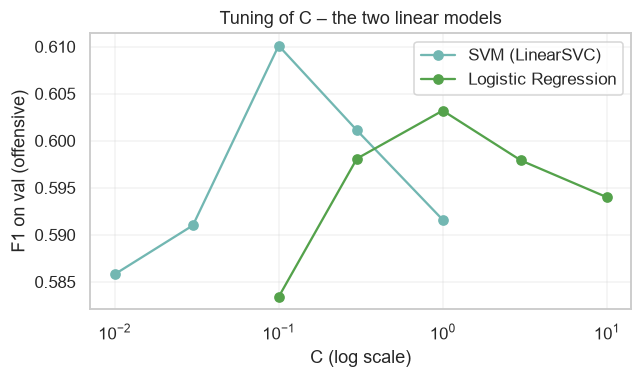

In [46]:
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(svm_grid["C"], svm_grid["F1 val (offensive)"], marker="o", color=MODEL_COLORS["SVM (LinearSVC)"], label="SVM (LinearSVC)")
ax.plot(lr_grid["C"], lr_grid["F1 val (offensive)"], marker="o", color=MODEL_COLORS["Logistic Regression"], label="Logistic Regression")
ax.set_xscale("log")
ax.set_xlabel("C (log scale)")
ax.set_ylabel("F1 on val (offensive)")
ax.set_title("Tuning of C – the two linear models")
ax.legend()
savefig(fig, "04_linear_models_tuning_C.png")

**Reading guide.** The two linear models are tuned on the same scale of `C`, so the curves can be read together: each has an optimum, with a drop on both sides (underfitting on the left, overfitting on the right).

<a id="5"></a>
## 5. Model 3 · Random Forest
Random Forest is non-linear but slower on a large sparse vocabulary, so the grid is kept small (number of trees × maximum depth). The code is in **`src/random_forest.py`**: `tune_random_forest()` keeps the combination with the best validation F1 of the offensive class. Limiting the depth is a simple way to reduce overfitting on text.

In [47]:
from src.random_forest import tune_random_forest

rf, best_rf_params, rf_grid = tune_random_forest(X_train_tfidf, y_train, X_val_tfidf, y_val)

print(f"Best parameters = {best_rf_params}  (F1 val = {rf_grid['F1 val (offensive)'].max():.4f})")
display(rf_grid)

Best parameters = {'n_estimators': 300, 'max_depth': 30}  (F1 val = 0.5880)


,n_estimators,max_depth,F1 val (offensive)
0,300,30,0.5880
1,100,30,0.5766
2,300,None,0.5362
3,100,None,0.5236


<a id="6"></a>
## 6. Model 4 · Naive Bayes
A fast probabilistic model that works on word counts / TF-IDF weights. The code is in **`src/naive_bayes.py`**. Naive Bayes has **no `class_weight` option**: to compensate for the class imbalance we use **equal class priors** (`fit_prior=False`). The smoothing value `alpha` is tuned on **val**. The cell also compares with the default behaviour (priors learned from the class frequencies) to justify this choice.

In [48]:
from src.naive_bayes import tune_naive_bayes, train_naive_bayes, DEFAULT_ALPHA_GRID as NB_ALPHA_GRID

nb, best_nb_alpha, nb_grid = tune_naive_bayes(X_train_tfidf, y_train, X_val_tfidf, y_val)

print(f"Best alpha = {best_nb_alpha}  (F1 val = {nb_grid['F1 val (offensive)'].max():.4f})")
if best_nb_alpha in (NB_ALPHA_GRID[0], NB_ALPHA_GRID[-1]):
    print("WARNING: the best alpha is at the edge of the grid -> extend DEFAULT_ALPHA_GRID in src/naive_bayes.py.")
display(nb_grid)

# Justification of fit_prior=False: same alpha, priors learned from the class frequencies
nb_default = train_naive_bayes(X_train_tfidf, y_train, alpha=best_nb_alpha, fit_prior=True)
f1_prior = f1_score(y_val, nb_default.predict(X_val_tfidf), pos_label=1)
print(f"\nF1 val with learned priors (fit_prior=True): {f1_prior:.4f}  vs  equal priors: {nb_grid['F1 val (offensive)'].max():.4f}")

Best alpha = 0.3  (F1 val = 0.5813)


,alpha,F1 val (offensive)
0,0.03,0.5738
1,0.10,0.5738
2,0.30,0.5813
3,1.00,0.5588



F1 val with learned priors (fit_prior=True): 0.4704  vs  equal priors: 0.5813


**Reading guide.** With priors learned from the data, the model favours the majority class (non-offensive) and misses many offensive tweets (low recall). Equal priors rebalance the decision and usually raise the F1 of the offensive class.

<a id="7"></a>
## 7. Model 5 · KNN
K-Nearest Neighbors classifies a tweet by the majority class among its closest training tweets. The code is in **`src/knn.py`**: the **cosine distance** is used because it suits TF-IDF vectors. `tune_knn()` tries several numbers of neighbours `k` and two voting schemes (`uniform`, `distance`). KNN has **no `class_weight` option**, so it naturally leans towards the majority class.

In [49]:
from src.knn import tune_knn, DEFAULT_K_GRID as KNN_K_GRID

knn, best_knn_params, knn_grid = tune_knn(X_train_tfidf, y_train, X_val_tfidf, y_val)

print(f"Best parameters = {best_knn_params}  (F1 val = {knn_grid['F1 val (offensive)'].max():.4f})")
best_k = best_knn_params["n_neighbors"]
if best_k == KNN_K_GRID[-1] or (best_k == KNN_K_GRID[0] and best_k > 1):
    print("WARNING: the best k is at the edge of the grid -> extend DEFAULT_K_GRID in src/knn.py.")
if best_k == 1:
    print("Note: k = 1 is the smallest possible value (the tweet copies the label of its single nearest neighbour):")
    print("      the model is very sensitive to noise, which confirms that KNN fits TF-IDF text poorly.")
display(knn_grid)

Best parameters = {'n_neighbors': 1, 'weights': 'uniform'}  (F1 val = 0.4015)
Note: k = 1 is the smallest possible value (the tweet copies the label of its single nearest neighbour):
      the model is very sensitive to noise, which confirms that KNN fits TF-IDF text poorly.


,n_neighbors,weights,F1 val (offensive)
0,1,uniform,0.4015
1,1,distance,0.4015
2,5,distance,0.3912
3,3,distance,0.3909
4,3,uniform,0.3903
5,5,uniform,0.3882
6,7,distance,0.3583
7,7,uniform,0.3564
8,11,distance,0.3388
9,11,uniform,0.3361


**Reading guide.** In a sparse, very high-dimensional space like TF-IDF, distances between tweets are all similar, so the nearest neighbours are weakly informative. KNN is therefore usually the weakest of the five models here, with a low recall on the offensive class; this is an expected limit of the method, not an error.

<a id="8"></a>
## 8. Results of the five models
Accuracy, precision, recall and F1 (offensive class) on **val**, with the confusion matrix of each model. All five models receive the same `X_train_tfidf` / `X_val_tfidf`. The detailed comparison, the justification of the best model and the error analysis are done in the evaluation notebook.

In [50]:
models = {"Logistic Regression": lr, "SVM (LinearSVC)": svm, "Random Forest": rf,
          "Naive Bayes": nb, "KNN": knn}

results = pd.DataFrame([scores(name, m, X_val_tfidf, y_val) for name, m in models.items()]).round(4)
display(results.sort_values("F1 (offensive)", ascending=False).reset_index(drop=True))

,Model,Accuracy,Precision,Recall,F1 (offensive)
0,SVM (LinearSVC),0.7258,0.6017,0.6187,0.6101
1,Logistic Regression,0.7198,0.5924,0.6144,0.6032
2,Random Forest,0.7153,0.5899,0.5861,0.5880
3,Naive Bayes,0.6964,0.5569,0.6078,0.5812
4,KNN,0.6488,0.4906,0.3399,0.4015


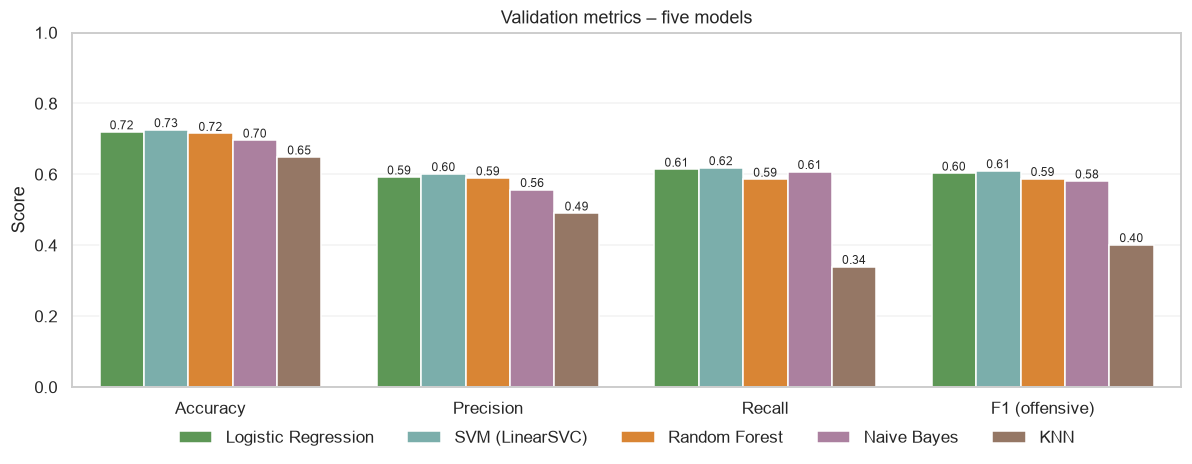

In [51]:
metrics = ["Accuracy", "Precision", "Recall", "F1 (offensive)"]
long = results.melt(id_vars="Model", value_vars=metrics, var_name="Metric", value_name="Score")

fig, ax = plt.subplots(figsize=(11, 4.4))
sns.barplot(data=long, x="Metric", y="Score", hue="Model", palette=MODEL_COLORS, ax=ax)
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=8)
ax.set_ylim(0, 1); ax.set_xlabel(""); ax.set_title("Validation metrics – five models")
ax.legend(title="", ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.08), frameon=False)
savefig(fig, "04_metrics_five_models.png")

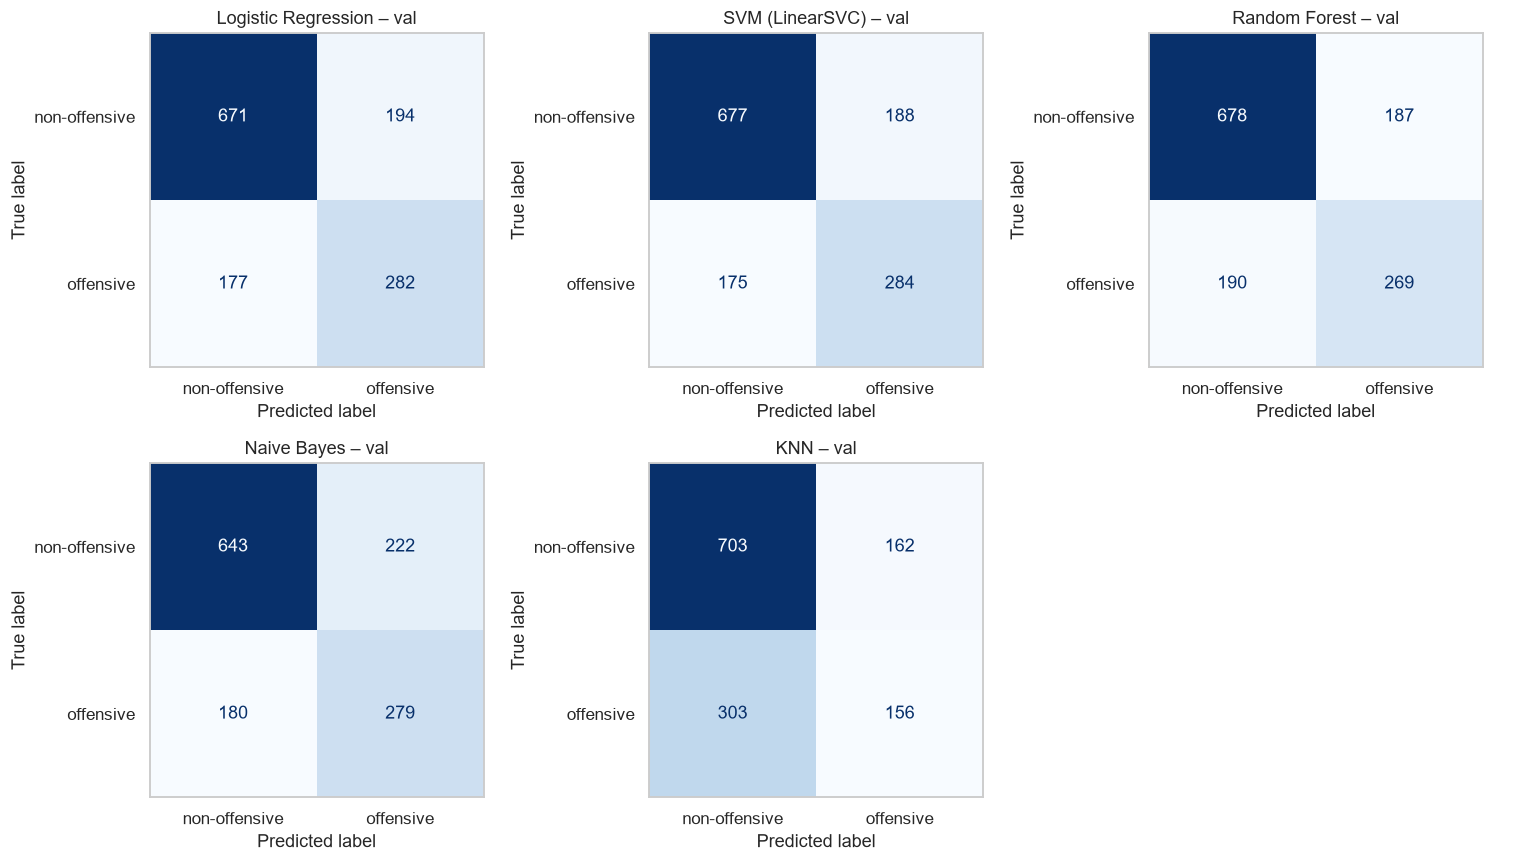

In [52]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, (name, m) in zip(axes.ravel(), models.items()):
    plot_confusion(ax, m, X_val_tfidf, y_val, f"{name} – val")
axes.ravel()[-1].axis("off")                      # 5 models, 6 panels
savefig(fig, "04_confusion_five_models.png")

 The **bottom-left** cell of a matrix counts offensive tweets that were missed (false negatives); the **top-right** cell counts non-offensive tweets wrongly flagged (false positives). Higher **recall** means fewer offensive tweets missed; higher **precision** means fewer false alarms; the F1 of the offensive class balances the two.

<a id="9"></a>
## 9. What the linear models learned
In a linear model the coefficients are directly readable: the largest positive weights push a tweet towards **offensive**, the most negative ones towards **non-offensive**. `top_terms_svm()` and `top_terms_logreg()` extract them, which checks that the models rely on meaningful words.

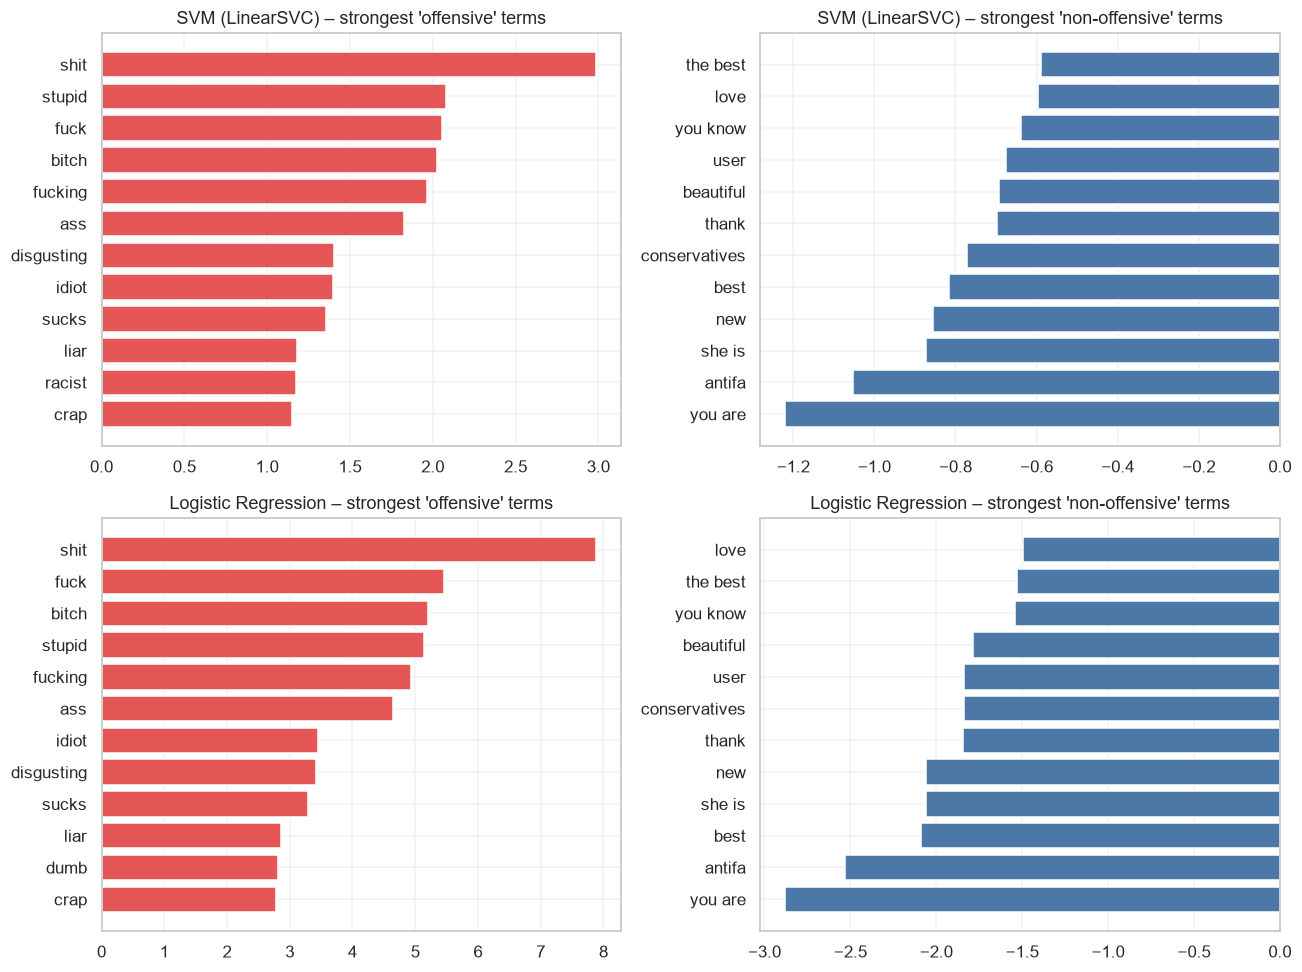

In [53]:
feature_names = tfidf.get_feature_names_out()
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for row, (name, model, fn) in enumerate([("SVM (LinearSVC)", svm, top_terms_svm),
                                         ("Logistic Regression", lr, top_terms_logreg)]):
    off, non = fn(model, feature_names, n=12)
    axes[row, 0].barh(off["term"][::-1], off["weight"][::-1], color=COLORS["offensive"])
    axes[row, 0].set_title(f"{name} – strongest 'offensive' terms")
    axes[row, 1].barh(non["term"], non["weight"], color=COLORS["non-offensive"])
    axes[row, 1].set_title(f"{name} – strongest 'non-offensive' terms")
savefig(fig, "04_linear_models_top_terms.png")

 Vulgar or insulting words are expected on the offensive side. If **topic words** (political groups, events…) appear among the strongest terms, the models partly learn *what people talk about* rather than *how they talk*, which is a limitation to mention in the conclusion of the project.

<a id="10"></a>
## 10. Conclusions
Generated from the results above, so it stays correct when the notebook is re-run with the final cleaning and TF-IDF. The final choice of the best model (and its justification) belongs to the evaluation notebook; here we only report what the validation results show.

In [54]:
print(f"Cleaning source: {CLEANING_SOURCE}\n")
ranked = results.sort_values("F1 (offensive)", ascending=False).reset_index(drop=True)
for rank, row in ranked.iterrows():
    tendency = ("catches more offensive tweets than it wrongly flags"
                if row["Recall"] >= row["Precision"] else
                "is more cautious: fewer false alarms, but more offensive tweets are missed")
    print(f"{rank + 1}. {row['Model']:<20} F1 (offensive) = {row['F1 (offensive)']:.3f}  "
          f"(P = {row['Precision']:.3f}, R = {row['Recall']:.3f}) -> {tendency}.")
print(f"\nStrongest candidate on val (F1 offensive): {ranked.loc[0, 'Model']}")
print(f"Weakest model on val                     : {ranked.loc[len(ranked) - 1, 'Model']}")

Cleaning source: src/preprocessing.py (Notebook 02)

1. SVM (LinearSVC)      F1 (offensive) = 0.610  (P = 0.602, R = 0.619) -> catches more offensive tweets than it wrongly flags.
2. Logistic Regression  F1 (offensive) = 0.603  (P = 0.592, R = 0.614) -> catches more offensive tweets than it wrongly flags.
3. Random Forest        F1 (offensive) = 0.588  (P = 0.590, R = 0.586) -> is more cautious: fewer false alarms, but more offensive tweets are missed.
4. Naive Bayes          F1 (offensive) = 0.581  (P = 0.557, R = 0.608) -> catches more offensive tweets than it wrongly flags.
5. KNN                  F1 (offensive) = 0.402  (P = 0.491, R = 0.340) -> is more cautious: fewer false alarms, but more offensive tweets are missed.

Strongest candidate on val (F1 offensive): SVM (LinearSVC)
Weakest model on val                     : KNN


<a id="11"></a>
## 11. Saving the results
Exported for the evaluation notebook, which builds the final comparison. The **validation predictions** let the evaluation notebook recompute metrics and study misclassified tweets without retraining. The final model is **not** saved here.

| Item | Location |
|---|---|
| Validation metrics of the five models | `results/metrics/models_validation_metrics.csv` |
| Tuning tables | `results/metrics/<model>_tuning.csv` |
| Validation predictions | `results/predictions/val_predictions_<model>.csv` |
| Figures | `results/figures/models/04_*.png` |

In [55]:
results.to_csv(MET_DIR / "models_validation_metrics.csv", index=False)

tuning_tables = {"logistic_regression": lr_grid, "svm": svm_grid, "random_forest": rf_grid,
                 "naive_bayes": nb_grid, "knn": knn_grid}
for key, table in tuning_tables.items():
    table.to_csv(MET_DIR / f"{key}_tuning.csv", index=False)

# Validation predictions: tweet, true label, predicted label
for key, (name, model) in zip(tuning_tables, models.items()):
    pd.DataFrame({"text": val_df["text"], "y_true": y_val,
                  "y_pred": model.predict(X_val_tfidf)}).to_csv(PRED_DIR / f"val_predictions_{key}.csv", index=False)

print("Saved:")
for folder in (MET_DIR, PRED_DIR):
    for p in sorted(folder.glob("*.csv")):
        print(" -", p.relative_to(PROJECT_ROOT))

Saved:
 - results\metrics\knn_tuning.csv
 - results\metrics\logistic_regression_tuning.csv
 - results\metrics\models_validation_metrics.csv
 - results\metrics\naive_bayes_tuning.csv
 - results\metrics\random_forest_tuning.csv
 - results\metrics\svm_tuning.csv
 - results\predictions\val_predictions_knn.csv
 - results\predictions\val_predictions_logistic_regression.csv
 - results\predictions\val_predictions_naive_bayes.csv
 - results\predictions\val_predictions_random_forest.csv
 - results\predictions\val_predictions_svm.csv
